# Why measure a test: size, power and the Monte Carlo error

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (the notebooks that open a committed artifact and read a `TestResult`)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- say what the size and the power of a validation test are, and why a test that has never been measured on data of known truth is a test of unknown error rates;
- read a simulation study as its five parts (aims, data-generating mechanisms, estimands, methods, performance measures) in a committed Contraste artifact;
- treat a rejection rate as an estimate: give its Monte Carlo standard error and its Wilson interval, and say how they shrink with the number of repetitions;
- tell the nominal level of a test from its true size, and read the exact rejection probability that needs no simulation for the count tests;
- replay a committed simulation row from its seed and its generator, and get the same count of rejections.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C22 of Contraste, "validating the validator": the measured size and power of the engine's validation tests. Nothing in it is real portfolio data. Every dataset was drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`), so the truth behind each number is known exactly. This notebook reads the family called `null`: every test with a p-value, run on data where its null hypothesis holds at the boundary and its assumptions are met. A test that is right should reject about 5% of the time at the 5% level there.

- **File read:** `data/derived/C22/null.json`, the key `outputs` (28 simulations, the generators that drew them, the size bounds) and `provenance`.
- **Where it comes from:** `data-pipeline/pipeline/cases/c22_validator.py` ran each simulation once, with a seed written next to its result. The notebook never reruns the 128,000 repetitions of the family; it reads them, and replays only the cheap rows that teach.

The next cell loads the artifact and prints what it holds, with the engine version that baked it beside the one installed.

In [2]:
# Load the null family and index its simulations by key; LANG picks the language of the bilingual labels
LANG = "en"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}

TRUTH = {"synthetic-known-truth": "synthetic, known truth"}
print("case:", null["case_id"], "|", "variant:", null["variant_id"], "|", TRUTH[null["provenance"]["truth_status"]])
print("baked by riskvalidation", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)
print("simulations:", len(rows), "|", "generators:", len(out["generators"]))
print("repetitions in the family:", sum(row["n_rep"] for row in rows.values()))
print("levels of the tests:", out["levels"])

case: C22 | variant: null | synthetic, known truth
baked by riskvalidation 0.4.3 | installed 0.8.1
simulations: 28 | generators: 14
repetitions in the family: 128000
levels of the tests: [0.05, 0.01]


## Method

A simulation study is an experiment, and Morris, White and Crowther (2019) give it a reporting structure called ADEMP: **A**ims, **D**ata-generating mechanisms, **E**stimands, **M**ethods and **P**erformance measures. The Contraste artifact carries all five:

| Part | In the artifact |
|---|---|
| Aims | the family (`null`: does each test hold its size?) and its panels |
| Data-generating mechanisms | `generators`, each with its configuration and its exact `truth` |
| Estimand | the probability that a test rejects at the level $\alpha$ |
| Methods | the registered test (`test_id`) under the policy's decision rule `p<0.05`, `p<0.01` |
| Performance measures | `rates` (the rejection rate with its standard error and interval), `exact` and `agrees` |

The size of a test is its rejection probability when the null hypothesis is true; the power is its rejection probability when a defect of known severity is planted. Both are probabilities, so a simulation can only estimate them. The steps below read one row of the artifact, treat its rate as an estimate, compare it with the exact value where one exists, and replay it.

### Step 1: one row of the study, read as ADEMP

The row `pd.binomial@null` is the binomial test on a portfolio of 1,000 obligors whose PD of 1% is exactly right. Its generator is `default_counts`, and the `truth` the generator wrote says what the data is: 10 expected defaults, a variance of 9.9 (independent obligors) and a null that holds at the boundary. The next cell prints the parts of the row.

In [3]:
# Read the aims, the generator and its truth, the method and the performance measures of one row
row = rows["pd.binomial@null"]
generator_spec = out["generators"][row["generator"]]
truth = generator_spec["truth"]

print("test:", row["test_id"], "|", row["label"][LANG])
print("obligors:", truth["obligors"][0][0], "|", "PD:", truth["pd_true"][0][0], "|", "PD applied:", truth["pd_forecast"][0][0])
print("generator:", generator_spec["name"], "| ref:", row["generator"])
print("expected defaults:", truth["expected_defaults"][0][0], "|", "variance of the count:", truth["variance_defaults"][0][0])
print("the null holds at the boundary:", truth["calibration_null_holds"])
print("repetitions:", row["n_rep"], "|", "seed:", row["seed"])
print("decision rules:", list(row["rates"]))

test: pd.binomial | Binomial
obligors: 1000 | PD: 0.01 | PD applied: 0.01
generator: default_counts | ref: port-1000-1pct
expected defaults: 10.0 | variance of the count: 9.9
the null holds at the boundary: True
repetitions: 4000 | seed: 3913381310
decision rules: ['p<0.05', 'p<0.01']


### Step 2: a rejection rate is an estimate

With $n$ repetitions and $k$ rejections, the rate $\hat r = k/n$ estimates the rejection probability. It carries a Monte Carlo standard error (Morris, White and Crowther, 2019, Table 6, "Rejection %"):

$$\widehat{\mathrm{SE}}(\hat r) = \sqrt{\hat r\,(1-\hat r)/n}$$

and an interval. Contraste reports the Wilson interval, which Brown, Cai and DasGupta (2001) recommend for a binomial proportion and which behaves well near 0, where small sizes sit. The engine's `Rate` holds the counts and computes both. The next cell builds a `Rate` from the committed counts and compares it with the numbers the artifact stored, then checks the standard error against its formula.

In [4]:
# Build a Rate from the committed counts and compare it with the stored rate, SE and Wilson interval
from riskvalidation.harness import Rate

committed = row["rates"]["p<0.05"]
rate = Rate(committed["rejections"], committed["n"])
low, high = rate.interval

print("rejections:", rate.rejections, "of", rate.n)
print("rate:", rate.rate, "|", "Monte Carlo SE:", round(rate.se, 6))
print("Wilson interval:", round(low, 6), "to", round(high, 6))
stored = [committed["rate"], committed["se"], committed["wilson_low"], committed["wilson_high"]]
print("equal to the committed row:", bool(np.allclose([rate.rate, rate.se, low, high], stored)))
print("SE from the formula:", round(float(np.sqrt(rate.rate * (1 - rate.rate) / rate.n)), 6))

rejections: 182 of 4000
rate: 0.0455 | Monte Carlo SE: 0.003295
Wilson interval: 0.039466 to 0.052406
equal to the committed row: True
SE from the formula: 0.003295


### Step 3: the nominal level is not the size

A test at level 5% is built to reject at most 5% of the time when its null holds. For a test that sees the data only through a default count $D$ of $n$ obligors (the binomial and the Jeffreys tests), there is a smallest count $k^*$ whose p-value falls below $\alpha$, and the test rejects exactly when $D \ge k^*$. Because $D$ is discrete, the true size is the tail probability of the count at $k^*$, and it is rarely $\alpha$:

$$P(\text{reject}) = P(D \ge k^*), \qquad D \sim \mathrm{Binomial}(n, \pi)$$

The engine finds $k^*$ by calling the registered test itself, so the exact value needs no simulation and checks the generator, the harness and the test together. The next cell asks for the critical count and the exact size of both tests at 5% and at 1%, for 1,000 obligors and a PD of 1%.

In [5]:
# Critical count and exact size of the binomial and Jeffreys tests (n = 1000, PD = 1%)
from riskvalidation.harness import critical_count, rejection_probability

for test in ("pd.binomial", "pd.jeffreys"):
    for alpha in (0.05, 0.01):
        k_star = critical_count(test, 1000, 0.01, alpha)
        exact = rejection_probability(test, 1000, 0.01, alpha)["probability"]
        print(f"{test:12s} level {alpha:.2f} | rejects from {k_star} defaults | exact size {exact:.6f}")

print("committed exact sizes, binomial:", rows["pd.binomial@null"]["exact"])
print("committed exact sizes, Jeffreys:", rows["pd.jeffreys@null"]["exact"])

pd.binomial  level 0.05 | rejects from 16 defaults | exact size 0.047871
pd.binomial  level 0.01 | rejects from 19 defaults | exact size 0.006905
pd.jeffreys  level 0.05 | rejects from 16 defaults | exact size 0.047871
pd.jeffreys  level 0.01 | rejects from 18 defaults | exact size 0.013833
committed exact sizes, binomial: {'p<0.05': 0.0478705858, 'p<0.01': 0.00690499477}
committed exact sizes, Jeffreys: {'p<0.05': 0.0478705858, 'p<0.01': 0.0138325817}


### Step 4: does the simulated rate agree with the exact value?

When an exact probability $p$ exists, the simulated rate must agree with it within its Monte Carlo error. The engine's `agrees` accepts a rate when

$$|\hat r - p| \le z\,\sqrt{p(1-p)/n}, \qquad z = 3.29 \ (\text{two-sided } 0.1\%)$$

The wide $z$ is deliberate: the study makes dozens of such comparisons, and a tight $z$ would flag noise. The next cell calls `agrees` on the two count tests and prints the standardised gap beside it, which is the definition of the criterion, not a second implementation of it.

In [6]:
# Compare each simulated rate with its exact probability with agrees, and print the standardised gap
from riskvalidation.harness import agrees

for key in ("pd.binomial@null", "pd.jeffreys@null"):
    for rule in ("p<0.05", "p<0.01"):
        c = rows[key]["rates"][rule]
        simulated = Rate(c["rejections"], c["n"])
        p_exact = rows[key]["exact"][rule]
        gap = (simulated.rate - p_exact) / np.sqrt(p_exact * (1 - p_exact) / simulated.n)
        print(f"{key:18s} {rule:7s} simulated {simulated.rate:.5f} | exact {p_exact:.5f} | z {gap:+.2f} | agrees {agrees(simulated, p_exact)}")

pd.binomial@null   p<0.05  simulated 0.04550 | exact 0.04787 | z -0.70 | agrees True
pd.binomial@null   p<0.01  simulated 0.00600 | exact 0.00690 | z -0.69 | agrees True
pd.jeffreys@null   p<0.05  simulated 0.03900 | exact 0.04787 | z -2.63 | agrees True
pd.jeffreys@null   p<0.01  simulated 0.01125 | exact 0.01383 | z -1.40 | agrees True


### Step 5: the size bound, for tests with no exact value

Most tests have no exact rejection probability. For them the question is one-sided: is the rate compatible with a true size of at most $\alpha$? The engine answers with a bound, $\alpha + z\sqrt{\alpha(1-\alpha)/n}$ with $z = 3.09$ (one-sided 0.1%), and `within_size` compares a rate with it. The artifact stores the bound for its 4,000 repetitions. The next cell reproduces the stored bound and applies `within_size` to the PSI test, which is calibrated, and to the normal test over five years, which is not.

In [7]:
# Reproduce the stored size bound and apply within_size to two tests
from riskvalidation.harness import size_bound, within_size

for alpha in (0.05, 0.01):
    print(f"level {alpha:.2f} | bound for 4000 repetitions {size_bound(alpha, 4000):.6f} | committed {out['size_bounds'][f'p<{alpha:.2f}']:.6f}")

for key in ("stability.psi@null", "pd.normal_multiperiod@null"):
    c = rows[key]["rates"]["p<0.05"]
    r = Rate(c["rejections"], c["n"])
    print(f"{key:28s} rate at 5% {r.rate:.5f} | within the bound {within_size(r, 0.05)}")

level 0.05 | bound for 4000 repetitions 0.060649 | committed 0.060649
level 0.01 | bound for 4000 repetitions 0.014862 | committed 0.014862
stability.psi@null           rate at 5% 0.05250 | within the bound True
pd.normal_multiperiod@null   rate at 5% 0.08375 | within the bound False


### Step 6: replay a committed row

Everything needed to repeat a row is in the artifact: the generator's configuration, the test, the number of repetitions and the seed. Each repetition draws from its own stream, `SeedSequence(seed).spawn(n_rep)`, so a repetition can be re-run alone and the whole row is exactly reproducible. The next cell rebuilds the generator from the committed configuration, runs `simulate` with the committed seed and compares the count of rejections with the artifact. The row was baked by an older engine than the one installed; if the test had changed, the counts would differ, and the cell would say so.

In [8]:
# Rebuild the generator from its committed configuration and replay the row with its committed seed
from riskvalidation.generators import DefaultCounts, feed_cell
from riskvalidation.harness import simulate

generator = DefaultCounts(**generator_spec["config"])
replay = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell())

for rule in ("p<0.05", "p<0.01"):
    print(f"{rule} | replay {replay.rates[rule].rejections} | committed {row['rates'][rule]['rejections']}")
same = all(replay.rates[r].rejections == row["rates"][r]["rejections"] for r in ("p<0.05", "p<0.01"))
print("identical to the committed row:", same, "|", "baked by", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

p<0.05 | replay 182 | committed 182
p<0.01 | replay 24 | committed 24
identical to the committed row: True | baked by 0.4.3 | installed 0.8.1


### Step 7: the Monte Carlo error shrinks with the repetitions

Because repetition $i$ always uses the same stream, a run of 100 repetitions is the first 100 of a run of 4,000. That makes a clean experiment: the same study stopped at four lengths. The standard error falls as $1/\sqrt{n}$, so a 4x longer run halves the interval. The next cell runs the study at 100, 400, 1,600 and 4,000 repetitions and draws each rate with its Wilson interval, beside the exact size and the nominal 5%.

n_rep   100 | rate 0.0600 | SE 0.0237 | interval width 0.0970
n_rep   400 | rate 0.0425 | SE 0.0101 | interval width 0.0403
n_rep  1600 | rate 0.0500 | SE 0.0054 | interval width 0.0214
n_rep  4000 | rate 0.0455 | SE 0.0033 | interval width 0.0129


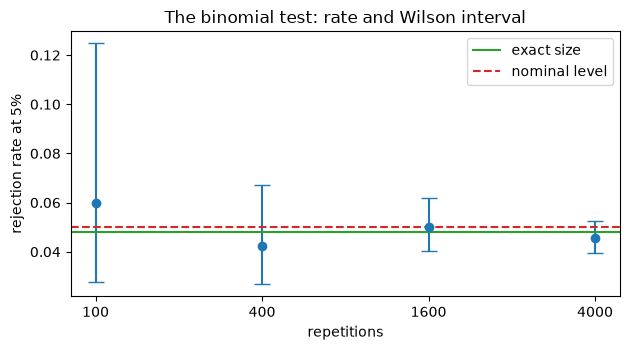

In [9]:
# Run the same study at four lengths and draw each rate with its Wilson interval
lengths = (100, 400, 1600, 4000)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for position, n_rep in enumerate(lengths):
    sim = simulate(row["test_id"], generator, n_rep=n_rep, seed=row["seed"], feed=feed_cell())
    r = sim.rate(0.05)
    low, high = r.interval
    print(f"n_rep {n_rep:5d} | rate {r.rate:.4f} | SE {r.se:.4f} | interval width {high - low:.4f}")
    ax.errorbar(position, r.rate, yerr=[[r.rate - low], [high - r.rate]], fmt="o", capsize=6, color="tab:blue")

ax.axhline(rows["pd.binomial@null"]["exact"]["p<0.05"], color="tab:green", label="exact size")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nominal level")
ax.set_xticks(range(len(lengths)))
ax.set_xticklabels([str(n) for n in lengths])
ax.set_xlabel("repetitions")
ax.set_ylabel("rejection rate at 5%")
ax.set_title("The binomial test: rate and Wilson interval")
ax.legend()
fig.tight_layout()
plt.show()

## Results

- **The row is an experiment.** `pd.binomial@null` fixes its aims (does the test hold its size?), its generator (1,000 independent obligors at a PD of 1%, 10 expected defaults), its method (the registered test with the rule `p<0.05` and `p<0.01`) and its performance measures. Nothing about it needs a real portfolio, because the truth is the generator's.
- **A rate is an estimate.** The binomial test rejected 182 of 4,000 repetitions at 5%: a rate of 4.55% with a Monte Carlo standard error of 0.33 points and a Wilson interval from 3.95% to 5.24%. The engine's `Rate` returns exactly the numbers the artifact stored, and the standard error equals its formula.
- **The nominal level is not the size.** The binomial test rejects from 16 defaults at the 5% level, and the probability of 16 or more defaults is 4.79%, not 5%, because the count is discrete. At the 1% level the binomial test has exact size 0.69% and the Jeffreys test 1.38%: the Jeffreys test is above its nominal level at 1% for this portfolio, with no simulation involved.
- **Simulation and exact value agree.** The largest standardised gap among the four comparisons is -2.63 (the Jeffreys test at 5%), inside the criterion of 3.29. A rate that agrees with its exact value is evidence that the generator, the harness and the test are wired as intended.
- **A bound for the rest.** With 4,000 repetitions a size above 6.06% at 5% (1.49% at 1%) is not Monte Carlo noise. The PSI test sits inside the bound with 5.25%; the normal test over five years sits outside it with 8.38%, a first sign that not every test holds its size (notebook 02 measures all of them).
- **The row replays.** With the committed seed the replay gives 182 and 24 rejections, the committed counts, although the artifact was baked by riskvalidation 0.4.3 and the installed engine is 0.8.1. That says the binomial test and this generator did not change on this row between the two versions; it says nothing about the other rows.
- **More repetitions, a narrower interval.** The interval is 9.7 points wide at 100 repetitions, 4.0 at 400, 2.1 at 1,600 and 1.3 at 4,000. A run of 100 repetitions cannot tell a test of size 4.8% from one of 6%; 4,000 can tell a few tenths of a point.

What this notebook does not show: the power of any test (notebook 03), the size of the other twenty tests (notebook 02), or what happens when the defaults of a portfolio are correlated (notebook 04).

## Summary

- The size of a test is its rejection rate when its null holds; the power is its rejection rate against a planted defect of known severity. Both are probabilities that a simulation estimates.
- A simulation study reports its aims, data-generating mechanisms, estimand, methods and performance measures (ADEMP), and every Contraste row carries them.
- A rejection rate has a Monte Carlo standard error, $\sqrt{\hat r(1-\hat r)/n}$, and a Wilson interval; a rate without them cannot be read.
- The nominal level is not the size. For the count tests the exact size needs no simulation and is the check the simulation must pass.
- A committed row replays exactly from its configuration and its seed, and a replay by another engine version is compared with the committed row, naming both versions.

**What to try next.** Replay another row of `null.json` from its seed (try `pd.jeffreys@null` or `stability.psi@null`), then read notebook 02, which measures the size of all twenty-one tests.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.3.1 (the Jeffreys test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- This repository: `docs/design/features/c22-validator/requirements.md` (the requirements the C22 measurements hold) and `data-pipeline/pipeline/cases/c22_validator.py` (the bake that wrote the artifact).